# **Рекомендация игр Steam** 

Цель системы — рекомендовать пользователю компьютерные игры из каталога Steam, с которыми он ранее не взаимодействовал, но которые могут соответствовать его предпочтениям. Рекомендуемым объектом является отдельная игра, идентифицируемая через AppID.


## **1. Данные** 

В работе используется датасет Steam Games, содержащий метаданные компьютерных игр, доступных на платформе Steam, и пользовательские отзывы об этих играх. Данные представлены двумя основными источниками: файлом games.json с описаниями игр и архивом Game Reviews.zip, содержащим CSV-файлы с отзывами пользователей.

Метаданные игр включают идентификатор игры (AppID), название, дату выхода, жанры, категории, разработчиков, издателей, теги, описание, стоимость и другие характеристики. 

В датасете есть две основные сущности:
- Игры (games.json) — метаданные объектов, которые потенциально можно рекомендовать: название, дата выпуска, жанры, категории, цена и другие характеристики, если они присутствуют в файле.
- Отзывы (Game Reviews/*.csv) — пользовательские отзывы об играх. Имя файла, например 8980_1910.csv, позволяет извлечь AppID = 8980, если первая часть имени действительно соответствует идентификатору игры.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F

import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

Перед запуском ячейки скачайте файл games.json с [сайта](https://data.mendeley.com/datasets/jxy85cr3th/2?utm_source=chatgpt.com)\
Разархивируйте Game Reviews и положите в папку рядом с games.json.

In [2]:
from pathlib import Path
import json
import re
import warnings

from tqdm.auto import tqdm
from IPython.display import display

TOP_K = 10

DATA_DIR = Path(".")
GAMES_PATH = DATA_DIR / "games.json"
REVIEWS_PATH = DATA_DIR / "Game Reviews"


assert GAMES_PATH.exists(), f"Не найден файл: {GAMES_PATH}"
assert REVIEWS_PATH.exists(), f"Не найден файл: {REVIEWS_PATH}"

## **1.1 Описания игр**

In [3]:
with GAMES_PATH.open("r", encoding="utf-8") as f:
    games_data = json.load(f)

print("Количество записей:", len(games_data))

games = pd.DataFrame.from_dict(games_data, orient="index")
games.index.name = "AppID"
games = games.reset_index()

games["AppID"] = games["AppID"].astype(str)

print("Количество признаков:", games.shape[1])
print("Список признаков:", games.columns)
display(games.head())

Количество записей: 65686
Количество признаков: 22
Список признаков: Index(['AppID', 'name', 'release_date', 'required_age', 'price',
       'detailed_description', 'about_the_game', 'short_description',
       'supported_languages', 'full_audio_languages', 'categories', 'genres',
       'positive', 'negative', 'estimated_owners', 'average_playtime_forever',
       'average_playtime_2weeks', 'median_playtime_forever',
       'median_playtime_2weeks', 'discount', 'peak_ccu', 'tags'],
      dtype='object')


,AppID,name,release_date,required_age,price,detailed_description,about_the_game,short_description,supported_languages,full_audio_languages,...,positive,negative,estimated_owners,average_playtime_forever,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks,discount,peak_ccu,tags
0,1724540,Welcome to Goodland,"Apr 28, 2023",0,16.99,Join our Discord! About the Game You could nev...,You could never have known you would end up in...,It is a strategy/adventure game set in a small...,[English],[],...,25,8,0 - 20000,0,0,0,0,0,0,"{'Choose Your Own Adventure': 332, 'Time Manag..."
1,2201840,그녀가 다시 노래할 때까지.,"Nov 14, 2022",0,4.99,ABOUT THE GAME 'Until She sings again' is a ro...,ABOUT THE GAME 'Until She sings again' is a ro...,My friend has become a girl after I came back ...,[Korean],[Korean],...,8,2,0 - 20000,0,0,0,0,0,0,"{'Simulation': 67, 'Visual Novel': 40, '2D': 3..."
2,1364180,Counter Operation Online,"Nov 1, 2020",0,14.99,Counter Operation Online (COO) shooter require...,Counter Operation Online (COO) shooter require...,Counter Operation Online ( COO ) revived by th...,[English],[English],...,1,1,0 - 20000,0,0,0,0,0,0,"{'Shooter': 50, 'FPS': 45, 'First-Person': 42,..."
3,2218750,Halls of Torment,"Sep 24, 2024",0,6.66,Halls of Torment is a horde survival game with...,Halls of Torment is a horde survival game with...,Slay hordes of terrifying monsters in this hor...,"[English, French, Italian, German, Spanish - S...","[English, Ukrainian]",...,24098,1044,500000 - 1000000,0,0,0,0,0,1492,"{'Action Roguelike': 662, 'Rogue-lite': 656, '..."
4,3262620,剑武玄幻之旅,"Oct 31, 2024",0,3.39,玄幻类文字挂机冒险游戏，探索一个系统丰富且娱乐快捷的放置世界 少年穿越异世，一路成长，屡遭奇...,玄幻类文字挂机冒险游戏，探索一个系统丰富且娱乐快捷的放置世界 少年穿越异世，一路成长，屡遭奇...,一款玄幻类的文字挂机冒险游戏，可放置可探索剧情，即刻进入一个系统丰富且娱乐快捷的挂机世界吧！,[Simplified Chinese],[],...,8,2,0 - 20000,0,0,0,0,15,23,"{'Casual': 63, 'Strategy': 54, 'Idler': 37, '2..."


In [4]:
import json
import ast
from collections import Counter
import pandas as pd

def extract_column_categories(series):
    """Считает количество игр с каждой категорией."""
    counts = Counter()

    for value in series.dropna():
        if isinstance(value, dict):
            categories = value.keys()
        elif isinstance(value, (list, tuple, set)):
            categories = value
        else:
            continue

        counts.update(set(categories))

    return counts

language_counts = extract_column_categories(games["supported_languages"])
tag_counts = extract_column_categories(games["tags"])

languages_df = pd.DataFrame(
    language_counts.most_common(),
    columns=["language", "game_count"]
)

tags_df = pd.DataFrame(
    tag_counts.most_common(),
    columns=["tag", "game_count"]
)

print("Уникальных языков:", len(languages_df))
print("Уникальных тегов:", len(tags_df))

Уникальных языков: 103
Уникальных тегов: 450


In [5]:
import matplotlib.pyplot as plt

def plot_categories_and_histogram(
    df,
    label_col,
    title,
    top_n=25,
    bins=50,
):
    counts = df["game_count"].dropna()

    fig, (ax1, ax2) = plt.subplots(
        1, 2,
        figsize=(16, max(6, top_n * 0.28)),
        gridspec_kw={"width_ratios": [1.4, 1]},
    )

    top = (
        df.sort_values("game_count", ascending=False)
          .head(top_n)
          .sort_values("game_count", ascending=True)
    )

    bars = ax1.barh(top[label_col], top["game_count"])
    ax1.bar_label(bars, fmt="%.0f", padding=3, fontsize=8)
    ax1.set_title(f"Топ-{top_n} категорий", loc="left", fontweight="bold")
    ax1.set_xlabel("Количество игр")
    ax1.set_ylabel("")
    ax1.spines[["top", "right", "left"]].set_visible(False)
    ax1.grid(axis="x", alpha=0.25)
    ax1.set_axisbelow(True)

    ax2.hist(counts, bins=bins, edgecolor="black", linewidth=0.7)
    ax2.set_title("Распределение частот", loc="left", fontweight="bold")
    ax2.set_xlabel("Количество игр с категорией")
    ax2.set_ylabel("Количество категорий")
    ax2.grid(axis="y", alpha=0.25)
    ax2.set_axisbelow(True)

    fig.suptitle(title, fontsize=16, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

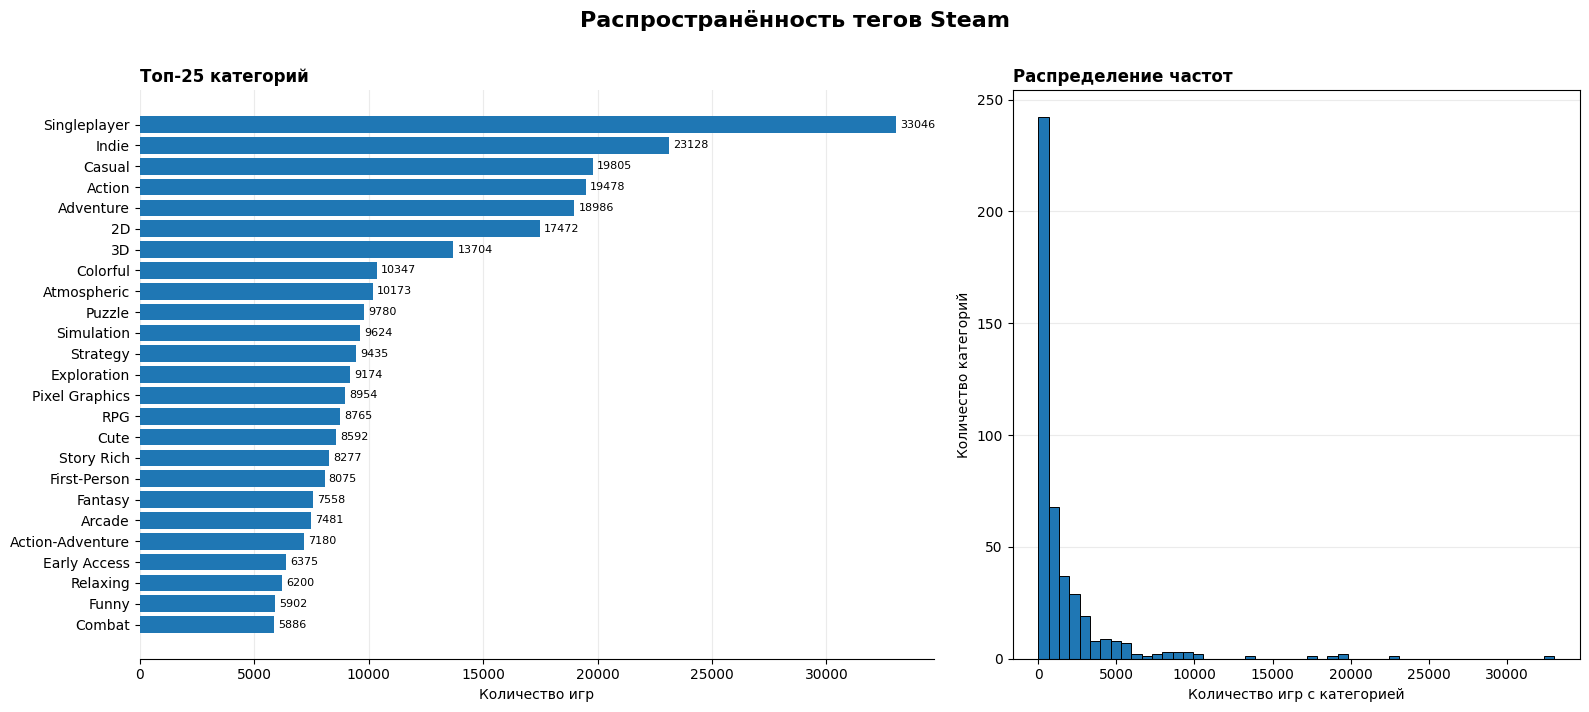

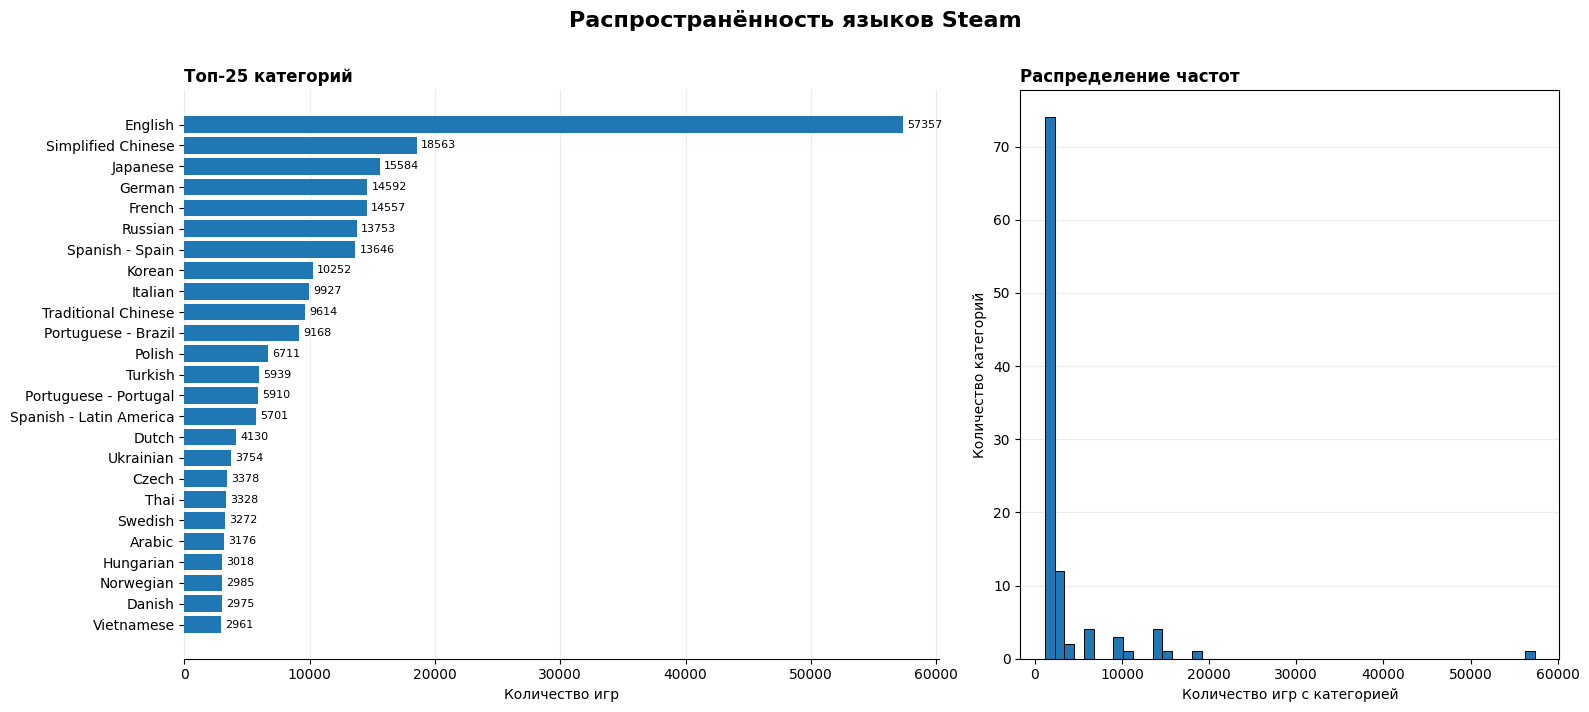

In [6]:
plot_categories_and_histogram(
    tags_df,
    label_col="tag",
    title="Распространённость тегов Steam",
    top_n=25,
)

plot_categories_and_histogram(
    languages_df,
    label_col="language",
    title="Распространённость языков Steam",
    top_n=25,
)

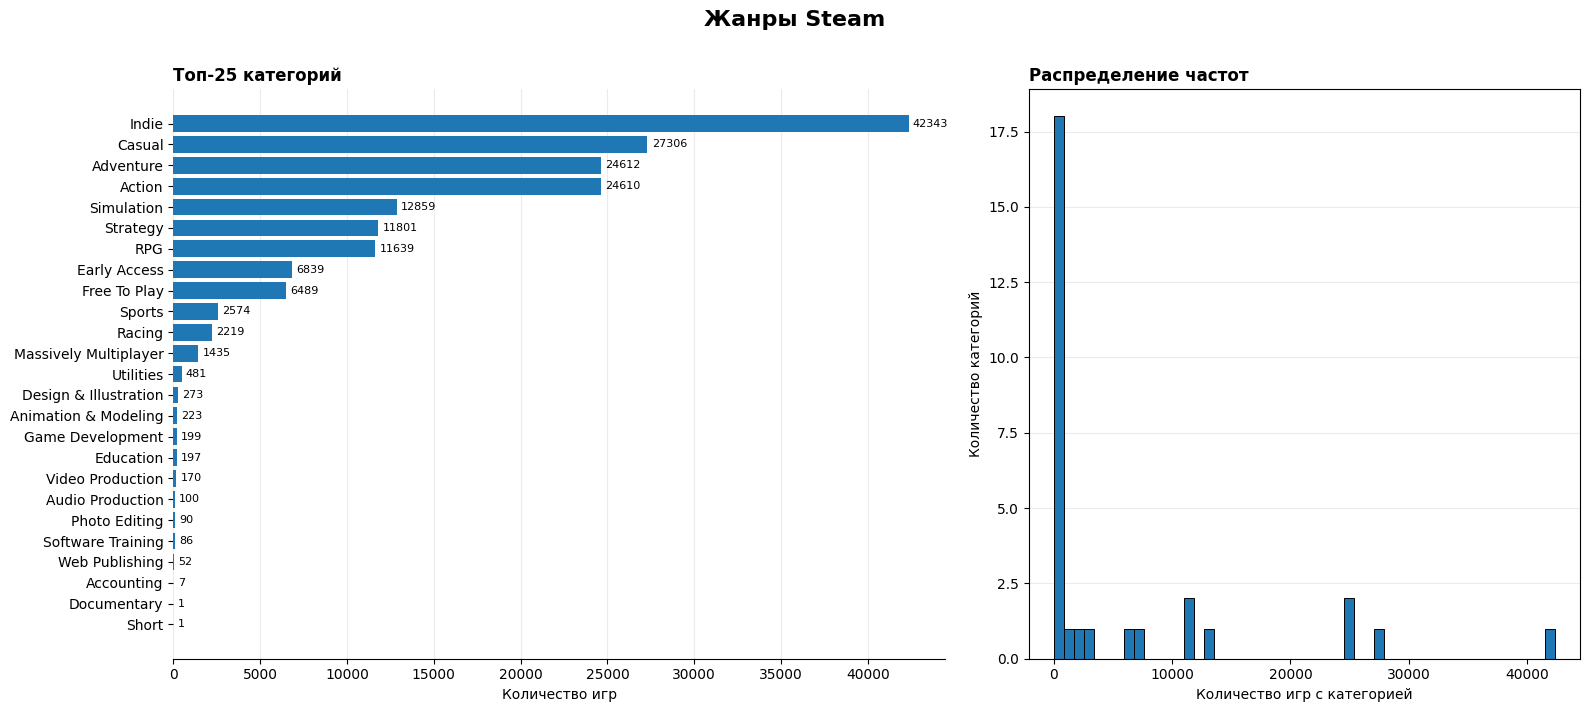

In [24]:
genres_counts = extract_column_categories(games["genres"])
genres_df = pd.DataFrame(
    genres_counts.most_common(),
    columns=["genres", "game_count"]
)

plot_categories_and_histogram(
    genres_df,
    label_col="genres",
    title="Жанры Steam",
    top_n=25,
)


На мой взгляд самые важные признаки (без учета отзывов): `genres`, `tags`. genres описывает основные игровые механики и жанровую принадлежность, например RPG, Strategy или Action, позволяя находить очень похожие игры. tags дополняет эту информацию. Мне кажется, что эти 2 признака в некотором роде могут заменить описание игры, которое я не хочу обрабатывать:)

In [25]:
ordinary_features = [
    "release_date",
    "price",
    "average_playtime_forever",
]

categorical_features = [
    "AppID",
    "genres",
    "tags",
]

interesting_features = ordinary_features + categorical_features

## **1.2 Пропущенные данные**

In [8]:
def is_empty_container(value):
    """Проверяет пустые строки и пустые контейнеры."""
    if isinstance(value, str):
        return value.strip() == ""

    if isinstance(value, (list, tuple, dict, set)):
        return len(value) == 0

    return False


def missing_report(df, features, dataset_name):
    """Сводка пропусков и пустых значений по выбранным признакам."""
    rows = []

    for col in features:
        series = df[col]
        null_mask = series.isna()

        missing_mask = null_mask | series.map(is_empty_container)
        n_missing = int(missing_mask.sum())

        rows.append({
            "feature": col,
            "missing_count": n_missing,
            "missing_rate": round(100 * n_missing / len(df), 2)
        })

    return pd.DataFrame(rows)

games_report = missing_report(
    games,
    interesting_features,
    "games",
)

display(
    games_report.sort_values(
        "missing_rate",
        ascending=False,
        na_position="last",
    )
)

,feature,missing_count,missing_rate
11,tags,20900,31.82
8,categories,5312,8.09
7,supported_languages,5124,7.80
9,genres,5100,7.76
3,average_playtime_forever,0,0.00
2,price,0,0.00
1,required_age,0,0.00
0,release_date,0,0.00
6,AppID,0,0.00
5,peak_ccu,0,0.00


## **1.3 Отзывы**

Теперь посмотрим на сами отзывы. Для начала было бы неплохо понять их примерное количество. 

Количество CSV-файлов: 23,107
Всего строк с отзывами: 31,832,390

Статистика количества строк на файл:


,count,mean,std,min,25%,50%,75%,max
row_count,23107.0,1377.608084,8349.501062,26.0,45.0,100.0,367.0,336460.0


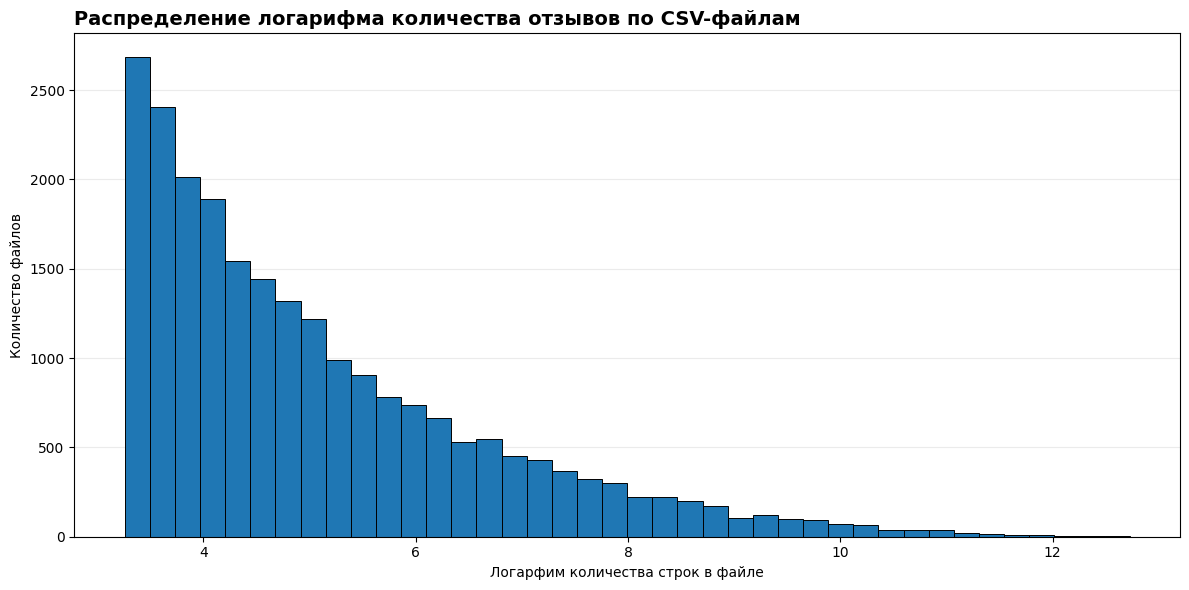

In [9]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


def analyze_review_files(reviews_path: Path):
    files = sorted(reviews_path.rglob("*.csv"))

    records = []

    for file in files:
        id, strlen = file.name[:-4].split('_')
        df_len = int(strlen)

        records.append({
            "AppID": id,
            "path": str(file),
            "row_count": df_len,
            "log_row_count": np.log(df_len),
        })

    df = pd.DataFrame(records)

    print(f"Количество CSV-файлов: {len(df):,}")
    print(f"Всего строк с отзывами: {df['row_count'].sum():,}")
    print("\nСтатистика количества строк на файл:")


    display(df["row_count"].describe().to_frame().T)

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.hist(df["log_row_count"], bins=40, edgecolor="black", linewidth=0.7)
    ax.set_title("Распределение логарифма количества отзывов по CSV-файлам", loc="left", fontsize=14,fontweight="bold",)
    ax.set_xlabel("Логарфим количества строк в файле")
    ax.set_ylabel("Количество файлов")
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()

    return df


reviews_files_df = analyze_review_files(REVIEWS_PATH)

Распределение очень сильно скошено вправо. Небольшое число популярных игр собирает непропорционально много отзывов.

Столбцы для каждого отзыва фиксированы: `user` , `playtime` , `post_date` , `helpfulness` , `review` , `recommend` , `early_access_review`. Опустим текстовую фичу `review`, и столбец `early_access_review`, который содержат много пропусков.\
Объединим все записи в один датасет. Сразу уберем все пропущенные значения, чтобы чуть-чуть уменьшить размер конечного датасета.  

In [10]:
review_columns = [
    "user",
    "playtime",
    "post_date",
    "recommend",
]

def load_all_reviews(reviews_files_df: pd.DataFrame) -> pd.DataFrame:
    frames = []

    missing = []
    for row in reviews_files_df.itertuples(index=False):
        df = pd.read_csv(row.path, usecols=review_columns)
        first_len = len(df)
        df = df.dropna(subset=review_columns)
        missing.append(first_len - len(df))
        df["AppID"] = int(row.AppID)
        frames.append(df)


    reviews_df = pd.concat(frames, ignore_index=True)
    return reviews_df, missing


reviews_df, missing = load_all_reviews(reviews_files_df)

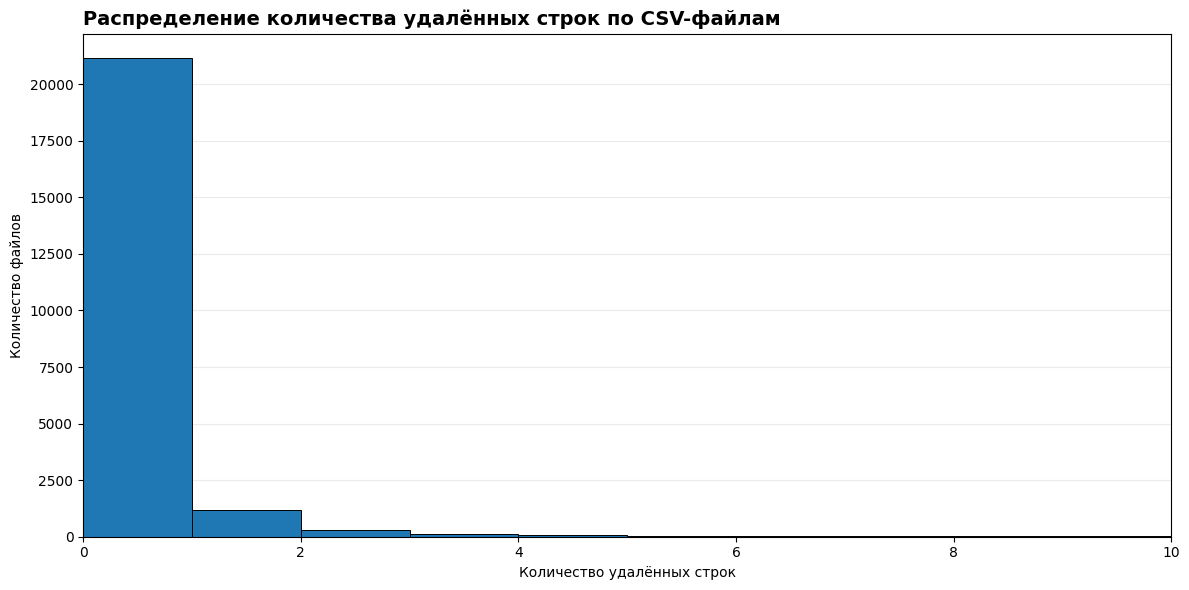

Всего удалено строк: 6,132
Файлов без пропусков: 21,168
Файлов с пропусками: 1,939
Максимум удалённых строк в одном файле: 1,062


In [11]:
fig, ax = plt.subplots(figsize=(12, 6))

missing_arr = np.array(missing)

ylim = 10

ax.hist(missing_arr[missing_arr <= ylim], edgecolor="black", linewidth=0.7)

ax.set_title(
    "Распределение количества удалённых строк по CSV-файлам",
    loc="left",
    fontsize=14,
    fontweight="bold",
)
ax.set_xlabel("Количество удалённых строк")
ax.set_ylabel("Количество файлов")
ax.set_xlim((0, ylim))
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print(f"Всего удалено строк: {sum(missing):,}")
print(f"Файлов без пропусков: {sum(x == 0 for x in missing):,}")
print(f"Файлов с пропусками: {sum(x > 0 for x in missing):,}")
print(f"Максимум удалённых строк в одном файле: {max(missing):,}")

In [12]:
print(f"Общее количество отзывов: {len(reviews_df)}")

Общее количество отзывов: 31826258


## **Итоговый Датасет**

Данных очень много, при этом они довольно качественные и почти не содержат пропусков. Поэтому сформируем воспроизводимую подвыборку из 2000000 взаимодействий.


## **2. Очистка**

Очистим метаданные игр и отзывы от пропусков и дубликатов. Оставим ограниченное число пользователей с достаточным количеством взаимодействий. Затем  выберем до MAX_ITEMS игр и MAX_USERS наиболее активных пользователей, ограничиваю выборку MAX_ROWS строками и формирую model_input и metadata, проверяя, что выполнены минимальные требования по числу взаимодействий, пользователей и игр.

In [121]:
from pathlib import Path
import gc
import hashlib
import heapq
import itertools
import json
import platform
import resource
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

MAX_ITEMS = 1_000
MAX_USERS = 50_000
MAX_ROWS = 2_000_000
MIN_ROWS = 100_000
MIN_ITEMS = 1_000
MIN_USERS = 1_000

MIN_TRAIN_POSITIVES = 3
K = 10
PRIMARY_METRIC = 'NDCG@10'
EXPERIMENT_SEED = 42

MODEL_ORDER = ['ItemKNN', 'iALS', 'EASE', 'FM', 'CustomTargetIALS']


In [122]:
def normalize_app_id(series):
    values = pd.to_numeric(series, errors="coerce")
    return values.map(
        lambda x: str(int(x)) if pd.notna(x) and x >= 0 and x.is_integer() else None
    )

def normalize_recommend(series):
    mapping = {
        "recommended": True,
        "not recommended": False,
        "true": True,
        "false": False,
        "1": True,
        "0": False,
    }
    if pd.api.types.is_bool_dtype(series):
        return series.astype("boolean")
    result = series.astype("string").str.strip().str.lower().map(mapping)
    unknown = series.notna() & result.isna()
    if unknown.any():
        raise ValueError(
            f"Неизвестные значения recommend: "
            f"{series[unknown].value_counts().head().to_dict()}"
        )
    return result.astype("boolean")


metadata = games[interesting_features].copy()
metadata = metadata.dropna(subset=["AppID"])
metadata["AppID"] = normalize_app_id(metadata["AppID"])
metadata = metadata.dropna(subset=["AppID"]).drop_duplicates("AppID")

metadata["release_date"] = pd.to_datetime(
    metadata["release_date"], errors="coerce", utc=True, format="mixed"
)
for col in ["price", "average_playtime_forever"]:
    metadata[col] = pd.to_numeric(metadata[col], errors="coerce")

for col in categorical_features:
    if col != "AppID":
        metadata[col] = metadata[col].map(
            lambda x: list(x) if isinstance(x, (list, tuple, set)) else []
        )

metadata = metadata[
    metadata["genres"].map(lambda x: len(x) > 0)
].copy()


In [123]:
model_input = reviews_df[
    ["user", "AppID", "recommend", "post_date"]
].copy()

model_input = model_input.dropna(
    subset=["user", "AppID", "recommend", "post_date"]
)
model_input["user"] = model_input["user"].astype(str)
model_input["AppID"] = normalize_app_id(model_input["AppID"])
model_input["recommend"] = normalize_recommend(model_input["recommend"])
model_input["post_date"] = pd.to_datetime(
    model_input["post_date"], errors="coerce", utc=True, format="mixed"
)
model_input = model_input.dropna(
    subset=["AppID", "recommend", "post_date"]
)
model_input["recommend"] = model_input["recommend"].astype(bool)

model_input = model_input[
    model_input["AppID"].isin(set(metadata["AppID"]))
].copy()
model_input = (
    model_input.sort_values("post_date", kind="stable")
    .drop_duplicates(["user", "AppID"], keep="last")
)

In [124]:
while True:
    old_len = len(model_input)
    item_counts = model_input["AppID"].value_counts()
    user_counts = model_input["user"].value_counts()
    model_input = model_input[
        model_input["AppID"].isin(item_counts[item_counts >= 2].index)
        & model_input["user"].isin(user_counts[user_counts >= 2].index)
    ].copy()
    if len(model_input) == old_len:
        break

def id_hash(value):
    return int.from_bytes(
        hashlib.blake2b(str(value).encode(), digest_size=8).digest(), "big"
    )

item_ids = model_input["AppID"].unique().tolist()
selected_items = heapq.nsmallest(
    min(MAX_ITEMS, len(item_ids)),
    item_ids,
    key=lambda x: (id_hash(x), x),
)
model_input = model_input[model_input["AppID"].isin(selected_items)].copy()


selected_users = model_input["user"].value_counts().head(MAX_USERS).index
model_input = model_input[model_input["user"].isin(selected_users)].copy()


if len(model_input) > MAX_ROWS:
    model_input = model_input.sample(
        n=MAX_ROWS, random_state=EXPERIMENT_SEED
    ).copy()

model_input = model_input.sort_values("post_date", kind="stable").reset_index(drop=True)
metadata = metadata[
    metadata["AppID"].isin(model_input["AppID"].unique())
].copy().reset_index(drop=True)

assert not model_input.duplicated(["user", "AppID"]).any()
assert model_input["recommend"].dtype == bool
assert model_input["post_date"].notna().all()
assert model_input["AppID"].dtype == object
assert metadata["AppID"].dtype == object

print(
    f"Взаимодействий: {len(model_input):,}\n"
    f"Пользователей: {model_input.user.nunique():,}\n"
    f"Игр: {model_input.AppID.nunique():,}\n"
    f"Метаданных: {len(metadata):,}"
)

Взаимодействий: 262,314
Пользователей: 50,000
Игр: 1,000
Метаданных: 1,000


## **3. Оценка**

Глобальные границы 60% / 80% дат задают train, validation, test. Совпадающие timestamp относятся к одному интервалу. Каталог — только игры, встречавшиеся в train и выпущенные к его концу. Когорта — пользователи с хотя бы `MIN_TRAIN_POSITIVES` положительными train-отзывами; она фиксирована без просмотра будущих оценок и одинакова для всех моделей и обоих этапов.

Рекомендуем игры без любого известного отзыва данного пользователя, включая отрицательные. Кандидаты — весь общий каталог, без случайных отрицательных кандидатов при оценке. Релевантность — **положительный будущий отзыв**, независимо от обучающего таргета. Новые объекты и пользователи вне когорты исключаются из warm-start оценки. Пользователи когорты без положительных будущих отзывов остаются с нулём в метриках.

**Основная метрика заранее — NDCG@10**, она поощряет высокую позицию понравившихся игр. **Recall@10** показывает долю будущих понравившихся игр в первой десятке.  После validation-подбора переобучаемся на train+validation и только затем считаем test.


In [125]:
def temporal_split(df, metadata):
    dates = df["post_date"].sort_values().reset_index(drop=True)
    cut1 = dates.iloc[int(0.6 * len(dates))]
    cut2 = dates.iloc[int(0.8 * len(dates))]

    train = df[df["post_date"] < cut1].copy()
    validation_raw = df[
        (df["post_date"] >= cut1) & (df["post_date"] < cut2)
    ].copy()
    test_raw = df[df["post_date"] >= cut2].copy()

    release_dates = metadata.set_index("AppID")["release_date"]
    released = set(release_dates[release_dates.notna() & (release_dates <= cut1)].index)
    catalog = sorted(set(train["AppID"]) & released)
    train = train[train["AppID"].isin(catalog)].copy()

    activity = train.loc[train["recommend"]].groupby("user").size()
    users = sorted(activity[activity >= MIN_TRAIN_POSITIVES].index)
    user_set, catalog_set = set(users), set(catalog)

    validation = validation_raw[
        validation_raw["user"].isin(user_set)
        & validation_raw["AppID"].isin(catalog_set)
    ].copy()
    test = test_raw[
        test_raw["user"].isin(user_set)
        & test_raw["AppID"].isin(catalog_set)
    ].copy()

    audit = {
        "train_end_exclusive": cut1.isoformat(),
        "validation_end_exclusive": cut2.isoformat(),
        "train_rows": len(train),
        "validation_rows": len(validation),
        "test_rows": len(test),
        "evaluation_users": len(users),
        "catalog_items": len(catalog),
    }
    return train, validation, test, users, catalog, audit

def ranking_metrics(recommendations, relevant, k=K):
    hits = np.array([it in relevant for it in recommendations[:k]], dtype=float)
    recall = hits.sum() / len(relevant) if relevant else 0.
    ideal = (1 / np.log2(np.arange(min(k, len(relevant))) + 2)).sum()
    dcg = (hits / np.log2(np.arange(len(hits)) + 2)).sum()
    return float(dcg / ideal) if ideal else 0., float(recall)

def evaluate(model, holdout, users, catalog):
    relevant = holdout[holdout.recommend].groupby('user').AppID.agg(set).to_dict()
    rows = []
    for user in users:
        recommendations = model.recommend(user, K, catalog)
        ids = [it for it, score in recommendations]
        ndcg, recall = ranking_metrics(ids, relevant.get(user, set()))
        rows.append({'user': user, PRIMARY_METRIC: ndcg, 'Recall@10': recall})
    per_user = pd.DataFrame(rows)
    return per_user[[PRIMARY_METRIC, 'Recall@10']].mean().to_dict(), per_user


In [126]:
train, validation, test, eval_users, catalog, protocol = temporal_split(model_input, metadata)
model_metadata = metadata[metadata.AppID.isin(catalog)].copy()

## **4. Модели и формулы**

Реализации находятся в `models/`\
Все модели используют `fit(train, model_metadata)`, `score(user)` и `recommend(user, k=10, candidates=catalog)`.


### **4.1. Item-based KNN**

Косинус $$S_{ij} = X_{*i}^{T}X_{*j} / (‖X_{*i}‖‖X_{*j}‖), diag(S)=0.$$ В строке оставляем k соседей. $$Score(u,i)=Σ_j X_{uj} S_{ji}.$$ Сходства считаются блоками.


In [127]:
import importlib
import models.fm as fm_module

importlib.reload(fm_module)

MetadataPreprocessor = fm_module.MetadataPreprocessor
FactorizationMachineRecommender = (
    fm_module.FactorizationMachineRecommender
)

In [128]:
from models.collaborative_filtering import ItemKNNRecommender


### **4.2. Базовый iALS**

Обучаем латентные векторы пользователей и игр, используя факт взаимодействия и его знак.

$$
p_{ui}=X_{ui},
\qquad
c_{ui}=1+\alpha O_{ui},
$$

где $\alpha\geq 0$ — коэффициент, определяющий дополнительную уверенность в наблюдаемых взаимодействиях.

Модель аппроксимирует target скалярным произведением латентных векторов пользователя $a_u\in\mathbb{R}^k$ и игры $b_i\in\mathbb{R}^k$. 
$$
\min_{\{a_u\},\{b_i\}}
\sum_{u,i}c_{ui}
\left(p_{ui}-a_u^\top b_i\right)^2
+
\lambda
\left(
\sum_u\|a_u\|_2^2+
\sum_i\|b_i\|_2^2
\right).
$$

Алгоритм ALS (Alternating Least Squares) поочерёдно оптимизирует факторы пользователей при фиксированных факторах игр и факторы игр при фиксированных факторах пользователей.

После обучения оценка игры для пользователя вычисляется как

$$
s(u,i)=a_u^\top b_i.
$$

Игры ранжируются по убыванию оценок, а уже встречавшиеся в обучающей выборке взаимодействия исключаются из рекомендаций.

In [129]:
from models.implicit_als import ImplicitALSRecommender


### **4.3. EASE**

Пусть $X\in\mathbb{R}^{U\times I}$ — матрица взаимодействий, где $U$ — число пользователей, $I$ — число игр. Модель ищет матрицу весов $B\in\mathbb{R}^{I\times I}$, минимизирующую ошибку восстановления с регуляризацией:

$$
\min_B \|X-XB\|_F^2+\lambda\|B\|_F^2,
\qquad \operatorname{diag}(B)=0.
$$

Ограничение на диагональ запрещает модели восстанавливать взаимодействие игры с помощью её собственного признака. Обозначим через $P$ обратную матрицу регуляризованной матрицы Грама:

$$
P=(X^\top X+\lambda I)^{-1}.
$$

Оптимальная матрица весов вычисляется по формуле

$$
B_{ij}=
\begin{cases}
-\dfrac{P_{ij}}{P_{jj}}, & i\ne j,\\[6pt]
0, & i=j.
\end{cases}
$$

Для пользователя $u$ оценки всех игр вычисляются как

$$
s_u=x_uB,
$$

где $x_u$ — строка матрицы взаимодействий пользователя. Уже просмотренные в обучающей выборке игры исключаются из рекомендаций.

Основное ограничение EASE — необходимость хранить и обрабатывать плотные матрицы размера $I\times I$. 

In [130]:
from models.ease import EASERecommender


### **4.4. Factorization Machine (FM)**

Factorization Machine (FM) моделирует взаимодействия между признаками пользователя и игры. В отличие от моделей, использующих только матрицу взаимодействий, FM позволяет учитывать метаданные объектов и тем самым использовать сходство игр по содержанию.

Для каждой пары «пользователь–игра» используются следующие признаки:

- **User ID** — идентификатор пользователя;
- **AppID** — идентификатор игры;
- **Genres** — жанры игры;
- **Tags** — категориальные теги, описывающие содержание и особенности игры.

Идентификаторы пользователей и игр кодируются отдельными индексами. Жанры и теги преобразуются в категориальные признаки вида `genre=action` и `tag=multiplayer`. Для каждого уникального токена создаётся отдельный признак в общем словаре. Признаки метаданных относятся к игре и совместно используются всеми пользователями, взаимодействующими с ней.

Пусть $x\in\mathbb{R}^n$ — разреженный вектор признаков пары «пользователь–игра», $w_0$ — глобальное смещение, $w_j$ — линейные веса, а $v_j\in\mathbb{R}^k$ — латентный вектор признака j. Тогда FM вычисляет логит:

$$
\hat y(x)=w_0+\sum_{j=1}^{n}w_jx_j
+\frac{1}{2}\sum_{f=1}^{k}
\left[
\left(\sum_{j=1}^{n}v_{jf}x_j\right)^2
-\sum_{j=1}^{n}v_{jf}^{\,2}x_j^2
\right].
$$

Для реализации градиентов FM используется тождество

$$
\frac{\partial \hat y(x)}{\partial v_{jf}}
=x_j\left(
\sum_{l=1}^{n}v_{lf}x_l-v_{jf}x_j
\right).
$$

Для заданного пользователя вычисляются логиты всех игр обучающего каталога. Игры ранжируются по убыванию логита, а уже встречавшиеся в обучении взаимодействия исключаются. 

In [131]:
from models.fm import FactorizationMachineRecommender


### **4.5. Временная модификация iALS**


Пусть $t_0$ — максимальная дата взаимодействия в текущей обучающей выборке, а $d_{ui}$ — количество дней между датой взаимодействия пользователя $u$ с игрой $i$ и $t_0$:

$$
d_{ui}=\frac{t_0-t_{ui}}{1\text{ день}}.
$$

Для положительного отзыва зададим временную целевую оценку:

$$
p_{ui}=
\begin{cases}
2^{-d_{ui}/H}, & \text{если отзыв положительный},\\
0, & \text{иначе},
\end{cases}
$$

Уверенность в наблюдаемых взаимодействиях остаётся такой же, как в базовой модели iALS:

$$
c_{ui}=1+\alpha r_{ui},
$$

где $r_{ui}$ — индикатор наблюдаемого взаимодействия, а $\alpha$ — коэффициент усиления уверенности. 
Для фиксированных латентных факторов объектов \(Y\) обновление вектора факторов пользователя \(x_u\) имеет вид

$$
x_u=
\left(Y^\top C^uY+\lambda I\right)^{-1}
Y^\top C^u p(u),
$$

где $C^u$ — диагональная матрица confidence пользователя, а $p(u)$ — вектор целевых значений для всех игр. Аналогично обновляются факторы объектов при фиксированных факторах пользователей.

При $H\to\infty$ целевые значения всех положительных отзывов стремятся к 1, поэтому восстанавливается стандартная бинарная постановка iALS. Временное затухание может улучшить рекомендации при изменяющихся интересах, но способно ухудшить качество при стабильных предпочтениях.

Временные целевые значения применяются только при обучении. На test релевантность по-прежнему оценивается по исходным бинарным меткам, без временного взвешивания.

In [132]:
from models.custom_ials import CustomTargetIALS


## **5. Подбор гиперпараметров на validation**


| Метод | Сетка | Запуски |
| --- | --- | --- |
| ItemKNN | neighbours ∈ {5,15,40}, block_size=128 | 3 |
| iALS | factors ∈ {8,16}, λ ∈ {0.5,5}, α=10, iterations=10 | 4 |
| EASE | λ ∈ {1,10,50}, max_items=1000 | 3 |
| FM | factors ∈ {8,16}, L2 ∈ {0.001,0.01}, epochs=10, lr=0.02 | 4 |
| Custom iALS | та же сетка iALS × H ∈ {60,180} дней | 8 |


In [133]:
def grid(**kwargs):
    return [dict(zip(kwargs, values)) for values in itertools.product(*kwargs.values())]

def search_spaces():
    als = grid(factors=[8, 16], regularization=[.5, 5.], alpha=[10.], iterations=[10], random_state=[EXPERIMENT_SEED])
    return {
        'ItemKNN': (ItemKNNRecommender, grid(n_neighbors=[5, 15, 40])),
        'iALS': (ImplicitALSRecommender, als),
        'EASE': (EASERecommender, grid(regularization=[1., 10., 50.])),
        'FM': (FactorizationMachineRecommender,
               grid(factors=[8, 16], epochs=[10], learning_rate=[.02], l2=[.001, .01], random_state=[EXPERIMENT_SEED])),
        'CustomTargetIALS': (CustomTargetIALS,
                            [dict(p, half_life_days=h) for p in als for h in [60., 180.]]),
    }

spaces = search_spaces()
trials = []
selected_parameters = {}
validation_scores = {}

def tune(name, constructor, configs):
    best_score = -np.inf
    for params in configs:
        tick = time.perf_counter()
        model = constructor(**params).fit(train, model_metadata)
        metrics, _ = evaluate(model, validation, eval_users, catalog)
        trials.append(dict(model=name, parameters=json.dumps(params, sort_keys=True),
                           fit_and_eval_seconds=time.perf_counter() - tick, **metrics))
        if metrics[PRIMARY_METRIC] > best_score:
            best_score = metrics[PRIMARY_METRIC]
            selected_parameters[name] = dict(params)
            validation_scores[name] = metrics
        del model
        gc.collect()
    print(name, '| лучший validation NDCG@10:', round(best_score, 4))
    print('Параметры:', selected_parameters[name])
    display(pd.DataFrame([row for row in trials if row['model'] == name]))


### **5.1. ItemKNN: validation**


In [134]:
tune('ItemKNN', *spaces['ItemKNN'])


ItemKNN | лучший validation NDCG@10: 0.0549
Параметры: {'n_neighbors': 40}


,model,parameters,fit_and_eval_seconds,NDCG@10,Recall@10
0,ItemKNN,"{""n_neighbors"": 5}",5.638820,0.047219,0.070499
1,ItemKNN,"{""n_neighbors"": 15}",2.890990,0.054325,0.087800
2,ItemKNN,"{""n_neighbors"": 40}",2.882622,0.054907,0.089709


### **5.2. iALS: validation**


In [135]:
tune('iALS', *spaces['iALS'])

iALS | лучший validation NDCG@10: 0.0365
Параметры: {'factors': 8, 'regularization': 0.5, 'alpha': 10.0, 'iterations': 10, 'random_state': 42}


,model,parameters,fit_and_eval_seconds,NDCG@10,Recall@10
0,iALS,"{""alpha"": 10.0, ""factors"": 8, ""iterations"": 10...",10.491650,0.036546,0.062436
1,iALS,"{""alpha"": 10.0, ""factors"": 8, ""iterations"": 10...",10.417963,0.036165,0.062005
2,iALS,"{""alpha"": 10.0, ""factors"": 16, ""iterations"": 1...",11.570276,0.029771,0.051253
3,iALS,"{""alpha"": 10.0, ""factors"": 16, ""iterations"": 1...",11.559903,0.028730,0.049980


### **5.3. EASE: validation**


In [136]:
tune('EASE', *spaces['EASE'])


EASE | лучший validation NDCG@10: 0.0583
Параметры: {'regularization': 50.0}


,model,parameters,fit_and_eval_seconds,NDCG@10,Recall@10
0,EASE,"{""regularization"": 1.0}",8.677258,0.056291,0.089236
1,EASE,"{""regularization"": 10.0}",8.660219,0.057322,0.091588
2,EASE,"{""regularization"": 50.0}",8.710563,0.058286,0.093065


### **5.4. FM: validation**


In [137]:
tune('FM', *spaces['FM'])


FM | лучший validation NDCG@10: 0.0389
Параметры: {'factors': 8, 'epochs': 10, 'learning_rate': 0.02, 'l2': 0.01, 'random_state': 42}


,model,parameters,fit_and_eval_seconds,NDCG@10,Recall@10
0,FM,"{""epochs"": 10, ""factors"": 8, ""l2"": 0.001, ""lea...",36.342179,0.036229,0.058461
1,FM,"{""epochs"": 10, ""factors"": 8, ""l2"": 0.01, ""lear...",35.904557,0.038876,0.056201
2,FM,"{""epochs"": 10, ""factors"": 16, ""l2"": 0.001, ""le...",54.063099,0.035683,0.058671
3,FM,"{""epochs"": 10, ""factors"": 16, ""l2"": 0.01, ""lea...",53.316533,0.038586,0.055613


### **5.5. CustomTargetIALS: validation**


In [138]:
tune('CustomTargetIALS', *spaces['CustomTargetIALS'])

CustomTargetIALS | лучший validation NDCG@10: 0.0353
Параметры: {'factors': 8, 'regularization': 5.0, 'alpha': 10.0, 'iterations': 10, 'random_state': 42, 'half_life_days': 180.0}


,model,parameters,fit_and_eval_seconds,NDCG@10,Recall@10
0,CustomTargetIALS,"{""alpha"": 10.0, ""factors"": 8, ""half_life_days""...",10.234403,0.031130,0.053929
1,CustomTargetIALS,"{""alpha"": 10.0, ""factors"": 8, ""half_life_days""...",10.127125,0.035027,0.059342
2,CustomTargetIALS,"{""alpha"": 10.0, ""factors"": 8, ""half_life_days""...",10.122139,0.031484,0.055074
3,CustomTargetIALS,"{""alpha"": 10.0, ""factors"": 8, ""half_life_days""...",10.131081,0.035302,0.059090
4,CustomTargetIALS,"{""alpha"": 10.0, ""factors"": 16, ""half_life_days...",11.367753,0.023227,0.041507
5,CustomTargetIALS,"{""alpha"": 10.0, ""factors"": 16, ""half_life_days...",11.271292,0.027374,0.049321
6,CustomTargetIALS,"{""alpha"": 10.0, ""factors"": 16, ""half_life_days...",11.254543,0.022912,0.041497
7,CustomTargetIALS,"{""alpha"": 10.0, ""factors"": 16, ""half_life_days...",11.232721,0.026894,0.048917


### **5.6. FM без метаданных: validation**


In [139]:
tune('FM_ID_only', FactorizationMachineRecommender,
     [dict(params, use_metadata=False) for params in spaces['FM'][1]])


FM_ID_only | лучший validation NDCG@10: 0.0488
Параметры: {'factors': 8, 'epochs': 10, 'learning_rate': 0.02, 'l2': 0.001, 'random_state': 42, 'use_metadata': False}


,model,parameters,fit_and_eval_seconds,NDCG@10,Recall@10
0,FM_ID_only,"{""epochs"": 10, ""factors"": 8, ""l2"": 0.001, ""lea...",27.734939,0.048835,0.072766
1,FM_ID_only,"{""epochs"": 10, ""factors"": 8, ""l2"": 0.01, ""lear...",27.395651,0.046760,0.070666
2,FM_ID_only,"{""epochs"": 10, ""factors"": 16, ""l2"": 0.001, ""le...",43.745080,0.048835,0.072766
3,FM_ID_only,"{""epochs"": 10, ""factors"": 16, ""l2"": 0.01, ""lea...",43.152527,0.046760,0.070666


### **5.7. Итог подбора: настройки замораживаются до test**


In [140]:
validation_search = pd.DataFrame(trials)
validation_table = pd.DataFrame([
    dict(model=name, **validation_scores[name], parameters=json.dumps(params, sort_keys=True))
    for name, params in selected_parameters.items()])
display(validation_table)
# Контрольный custom с ТОЧНО теми же факторами, regularization, alpha и iterations, что у iALS.
selected_parameters['Custom_matched_iALS'] = dict(selected_parameters['iALS'],
    half_life_days=selected_parameters['CustomTargetIALS']['half_life_days'])
frozen_parameters = json.loads(json.dumps(selected_parameters))


,model,NDCG@10,Recall@10,parameters
0,ItemKNN,0.054907,0.089709,"{""n_neighbors"": 40}"
1,iALS,0.036546,0.062436,"{""alpha"": 10.0, ""factors"": 8, ""iterations"": 10..."
2,EASE,0.058286,0.093065,"{""regularization"": 50.0}"
3,FM,0.038876,0.056201,"{""epochs"": 10, ""factors"": 8, ""l2"": 0.01, ""lear..."
4,CustomTargetIALS,0.035302,0.059090,"{""alpha"": 10.0, ""factors"": 8, ""half_life_days""..."
5,FM_ID_only,0.048835,0.072766,"{""epochs"": 10, ""factors"": 8, ""l2"": 0.001, ""lea..."


## **6. Обучение**

Теперь все настройки выбраны. Обучаемся заново на train+validation, исключаем известные игры из обоих интервалов, каталог и когорта остаются прежними. У custom временная точка отсчёта обновляется до конца текущего обучающего набора. Все пять обязательных моделей оцениваются в порядке задания; затем выполняются две абляции.


In [141]:
final_train = pd.concat([train, validation], ignore_index=True)
final_results = []
test_per_user = {}

def evaluate_final(name, constructor):
    tick = time.perf_counter()
    model = constructor(**frozen_parameters[name]).fit(final_train, model_metadata)
    fit_seconds = time.perf_counter() - tick
    tick = time.perf_counter()
    metrics, per_user = evaluate(model, test, eval_users, catalog)
    final_results.append(dict(model=name, **metrics, fit_seconds=fit_seconds,
        evaluation_seconds=time.perf_counter() - tick,
        parameters=json.dumps(frozen_parameters[name], sort_keys=True)))
    test_per_user[name] = per_user
    display(pd.DataFrame([final_results[-1]]))
    del model
    gc.collect()


### **6.1. ItemKNN: test**


In [142]:
evaluate_final('ItemKNN', spaces['ItemKNN'][0])


,model,NDCG@10,Recall@10,fit_seconds,evaluation_seconds,parameters
0,ItemKNN,0.067346,0.105132,0.563814,2.473537,"{""n_neighbors"": 40}"


### **6.2. iALS: test**


In [143]:
evaluate_final('iALS', spaces['iALS'][0])


,model,NDCG@10,Recall@10,fit_seconds,evaluation_seconds,parameters
0,iALS,0.043182,0.071381,8.400003,2.07757,"{""alpha"": 10.0, ""factors"": 8, ""iterations"": 10..."


### **6.3. EASE: test**


In [144]:
evaluate_final('EASE', spaces['EASE'][0])


,model,NDCG@10,Recall@10,fit_seconds,evaluation_seconds,parameters
0,EASE,0.069946,0.106739,0.428748,8.145067,"{""regularization"": 50.0}"


### **6.4. FM: test**


In [145]:
evaluate_final('FM', spaces['FM'][0])


,model,NDCG@10,Recall@10,fit_seconds,evaluation_seconds,parameters
0,FM,0.043341,0.064743,27.510192,10.083335,"{""epochs"": 10, ""factors"": 8, ""l2"": 0.01, ""lear..."


### **6.5. CustomTargetIALS: test**


In [146]:
evaluate_final('CustomTargetIALS', spaces['CustomTargetIALS'][0])


,model,NDCG@10,Recall@10,fit_seconds,evaluation_seconds,parameters
0,CustomTargetIALS,0.041145,0.066666,8.183457,2.001443,"{""alpha"": 10.0, ""factors"": 8, ""half_life_days""..."


### **6.6. FM без метаданных**

In [154]:
evaluate_final('FM_ID_only', FactorizationMachineRecommender)

,model,NDCG@10,Recall@10,fit_seconds,evaluation_seconds,parameters
0,FM_ID_only,0.054966,0.080876,24.273575,4.844111,"{""epochs"": 10, ""factors"": 8, ""l2"": 0.001, ""lea..."


### **6.7. Эксп затухание**

In [155]:
evaluate_final('Custom_matched_iALS', CustomTargetIALS)

,model,NDCG@10,Recall@10,fit_seconds,evaluation_seconds,parameters
0,Custom_matched_iALS,0.041022,0.065662,8.254618,1.994866,"{""alpha"": 10.0, ""factors"": 8, ""half_life_days""..."


## **7. Общая таблица сравнения при K=10**


,model,NDCG@10,Recall@10,fit_seconds,evaluation_seconds,parameters
0,ItemKNN,0.067346,0.105132,0.563814,2.473537,"{""n_neighbors"": 40}"
1,iALS,0.043182,0.071381,8.400003,2.077570,"{""alpha"": 10.0, ""factors"": 8, ""iterations"": 10..."
2,EASE,0.069946,0.106739,0.428748,8.145067,"{""regularization"": 50.0}"
3,FM,0.043341,0.064743,27.510192,10.083335,"{""epochs"": 10, ""factors"": 8, ""l2"": 0.01, ""lear..."
4,CustomTargetIALS,0.041145,0.066666,8.183457,2.001443,"{""alpha"": 10.0, ""factors"": 8, ""half_life_days""..."


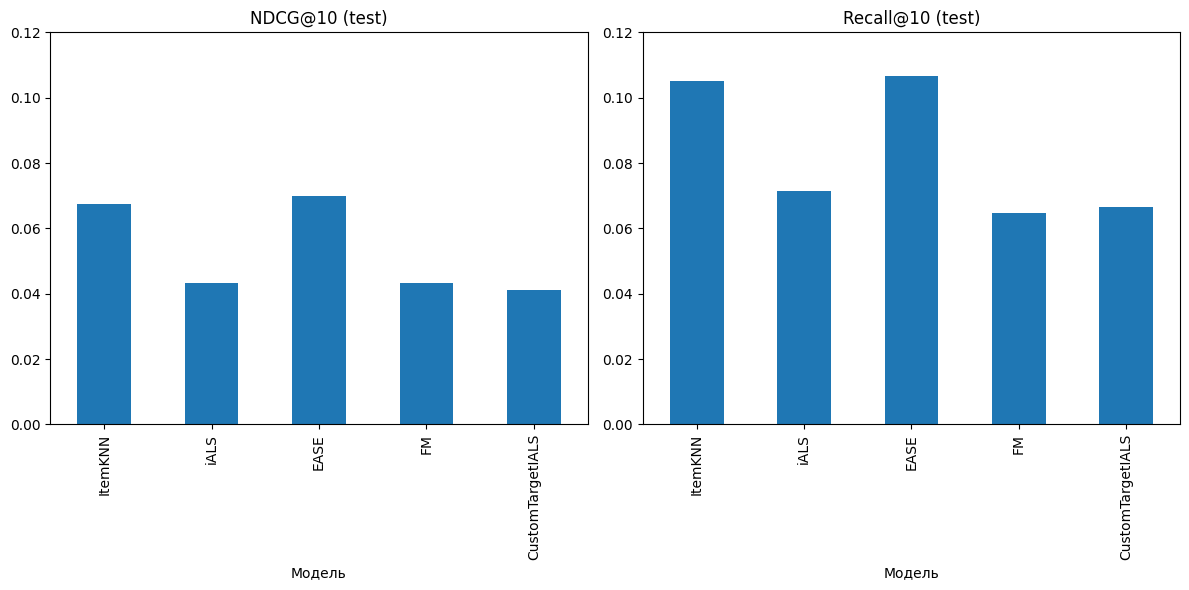

In [156]:
results = pd.DataFrame(final_results)
assert results.model.is_unique, 'Ячейки test запускались повторно: выполните раздел 6 заново с его первой ячейки'
required_results = results.set_index('model').loc[MODEL_ORDER].reset_index()
display(required_results)
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for axis, metric in zip(axes, [PRIMARY_METRIC, 'Recall@10']):
    required_results.set_index('model')[metric].plot.bar(ax=axis)
    axis.set(title=metric + ' (test)', ylim=(0, 0.12), xlabel='Модель')
fig.tight_layout()
plt.show()


### **7.1. Влияние метаданных и целевого сигнала**

Сравним пары на одних пользователях с помощью bootstrap по 1000 повторов


In [158]:
rng = np.random.default_rng(EXPERIMENT_SEED)
comparison_rows = []
for left, right in [('FM', 'FM_ID_only'), ('CustomTargetIALS', 'iALS'), ('Custom_matched_iALS', 'iALS')]:
    left_scores = test_per_user[left].set_index('user')[PRIMARY_METRIC]
    right_scores = test_per_user[right].set_index('user')[PRIMARY_METRIC]
    diff = (left_scores - right_scores).to_numpy()
    bootstrapped = np.array([rng.choice(diff, len(diff), replace=True).mean() for _ in range(1000)])
    low, high = np.quantile(bootstrapped, [.025, .975])
    comparison_rows.append(dict(comparison=f'{left} - {right}', delta=float(diff.mean()),
        ci_low=float(low), ci_high=float(high),
        interpretation='Уверенного различия нет' if low <= 0 <= high else
                       ('Первая модель лучше' if low > 0 else 'Вторая модель лучше')))
comparisons = pd.DataFrame(comparison_rows)
display(comparisons)
best_model = required_results.sort_values(PRIMARY_METRIC, ascending=False, kind='stable').iloc[0]
print('Лучшая моделька:', best_model['model'], '| NDCG@10:', round(best_model[PRIMARY_METRIC], 4))


,comparison,delta,ci_low,ci_high,interpretation
0,FM - FM_ID_only,-0.011625,-0.012749,-0.010573,Вторая модель лучше
1,CustomTargetIALS - iALS,-0.002037,-0.004208,0.000019,Уверенного различия нет
2,Custom_matched_iALS - iALS,-0.002159,-0.004213,-0.000193,Вторая модель лучше


Лучшая моделька: EASE | NDCG@10: 0.0699


Добавление метаданных ухудшило результат FM, использующей только идентификаторы пользователей и игр. Это может быть связано с переобучением или недообучением модели.
Временная модификация CustomTargetIALS, использующая экспоненциальное затухание, оказалась сравнима с обычным iALS.

## **Выводы**

Анализ показал, что данные сильно разрежены. При этом распределение количества отзывов по играм сильно скошено: небольшое число популярных игр получает непропорционально много отзывов. Из-за этого построение хорошей рекомендательной системы становится сложным.\
Были реализованы и сравнены пять рекомендательных моделей с использованием единых метрик качества.
Лучшее качество рекомендаций показала EASE: NDCG@10 = 0,069946, Recall@10 = 0,106739. Она немного превзошла ItemKNN и при этом обучалась быстрее (0,43 с против 0,56 с). iALS, FM и CustomTargetIALS показали более низкие метрики, причём FM обучалась дольше всего (27,51 с а до сокращения количества данных не досчитывалась и за час). Оказалось, что усложнение модели не обязательно приводит к улучшению рекомендаций.

## **Ссылки**:

[Датасет](https://data.mendeley.com/datasets/jxy85cr3th/2?utm_source=chatgpt.com)\
[Steam-Games-Scraper](https://github.com/FronkonGames/Steam-Games-Scraper)